<a href="https://colab.research.google.com/github/Prabuddhm98/Dav-lab/blob/main/airbnb_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
       CustomerID         Age  Annual Inco

In [ ]:
# Check missing values and duplicates
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)
df.drop_duplicates(subset='CustomerID', inplace=True)

# Check final dataset
print("Missing values:\n", df.isnull().sum())
print("Cleaned shape:", df.shape)

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicates: 0
Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Cleaned shape: (200, 5)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Encode gender
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

# Normalize numerical columns
scaler = MinMaxScaler()
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']] = scaler.fit_transform(
    df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
)

print(df.head())

   CustomerID  Gender       Age  Annual Income (k$)  Spending Score (1-100)
0           1       0  0.019231            0.000000                0.387755
1           2       0  0.057692            0.000000                0.816327
2           3       1  0.038462            0.008197                0.051020
3           4       1  0.096154            0.008197                0.775510
4           5       1  0.250000            0.016393                0.397959


In [ ]:
# Reload original dataset for analysis
df = pd.read_csv("Mall_Customers.csv")

# Statistical analysis
print(df.describe())

# Gender distribution
print(df['Gender'].value_counts())

# Average age, income and spending score
print(df[['Age', 'Annual Income (k$)',
          'Spending Score (1-100)']].mean())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000
Gender
Female    112
Male       88
Name: count, dtype: int64
Age                       38.85
Annual Income (k$)        60.56
Spending Score (1-100)    50.20
dtype: float64


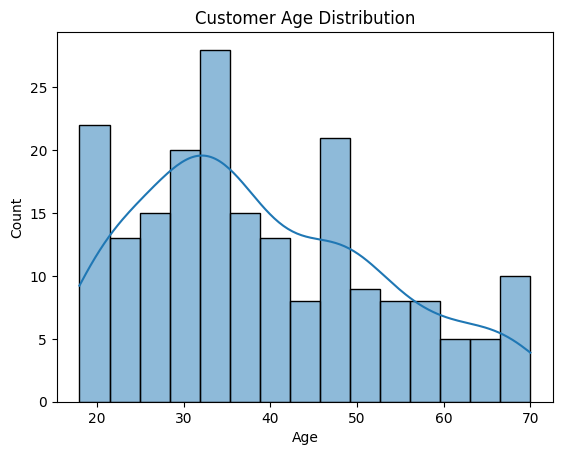

In [ ]:
#devide age column into 15 parts for histogram
sns.histplot(df['Age'], bins=15, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.show()

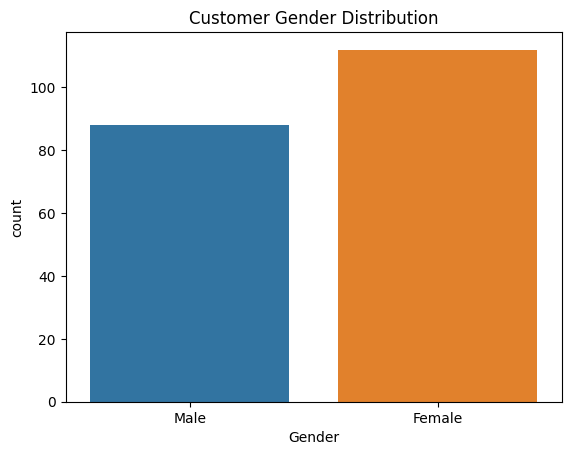

In [ ]:
sns.countplot(data=df, x='Gender', hue='Gender', legend=False)
plt.title("Customer Gender Distribution")
plt.show()

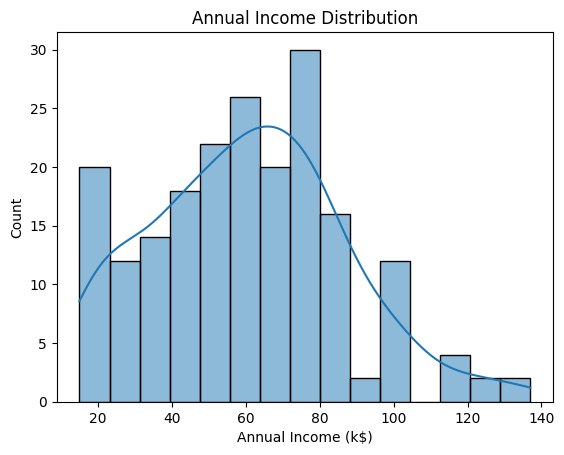

In [ ]:
sns.histplot(df['Annual Income (k$)'], bins=15, kde=True)
plt.title("Annual Income Distribution")
plt.show()

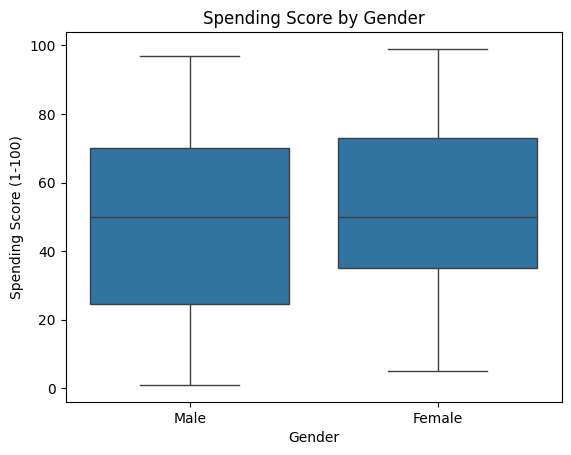

In [ ]:
sns.boxplot(data=df, x='Gender', y='Spending Score (1-100)')
plt.title("Spending Score by Gender")
plt.show()

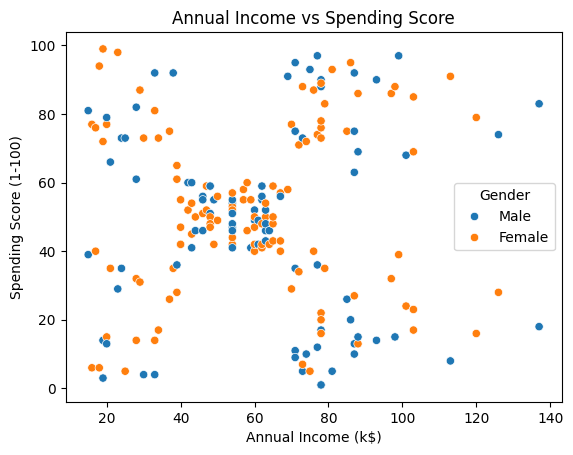

In [ ]:
sns.scatterplot(data=df, x='Annual Income (k$)',
                y='Spending Score (1-100)', hue='Gender')
plt.title("Annual Income vs Spending Score")
plt.show()

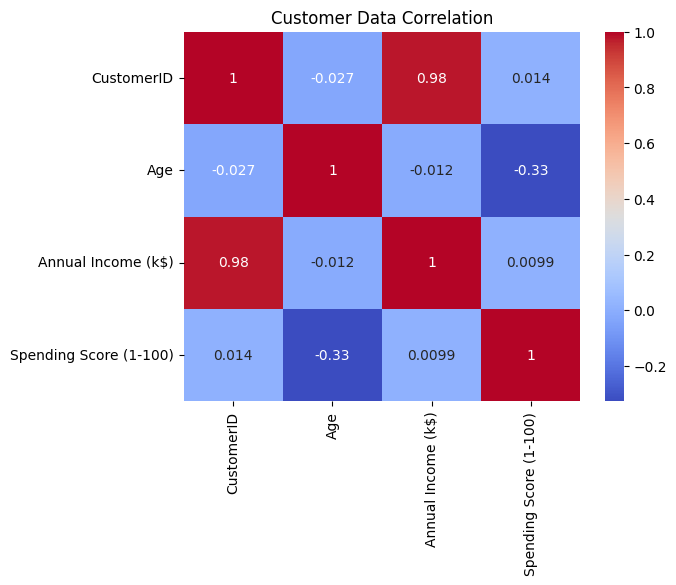

In [ ]:
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')
plt.title("Customer Data Correlation")
plt.show()

In [ ]:
# Average customer age
print("Average Age:", round(df['Age'].mean(), 2))

# Average annual income
print("Average Income:", round(df['Annual Income (k$)'].mean(), 2))

# Average spending score
print("Average Spending Score:",
      round(df['Spending Score (1-100)'].mean(), 2))

# Most common gender
print("Most Common Gender:", df['Gender'].mode()[0])

# Highest income customer
print("Highest Annual Income:",
      df['Annual Income (k$)'].max())

# Highest spending score
print("Highest Spending Score:",
      df['Spending Score (1-100)'].max())

# Age group analysis
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 40, 60, 100],
    labels=['Young', 'Adult', 'Middle-aged', 'Senior']
)

print("\nCustomers by Age Group:")
print(df['Age Group'].value_counts())

# Average spending by gender
print("\nAverage Spending by Gender:")
print(df.groupby('Gender')['Spending Score (1-100)'].mean())

Average Age: 38.85
Average Income: 60.56
Average Spending Score: 50.2
Most Common Gender: Female
Highest Annual Income: 137
Highest Spending Score: 99

Customers by Age Group:
Age Group
Adult          84
Middle-aged    61
Young          38
Senior         17
Name: count, dtype: int64

Average Spending by Gender:
Gender
Female    51.526786
Male      48.511364
Name: Spending Score (1-100), dtype: float64


In [ ]:
print("========== FINAL CONCLUSIONS ==========")

print("Total Customers:", len(df))

print("Average Customer Age:",
      round(df['Age'].mean(), 2))

print("Average Annual Income:",
      round(df['Annual Income (k$)'].mean(), 2))

print("Average Spending Score:",
      round(df['Spending Score (1-100)'].mean(), 2))

print("Most Common Gender:", df['Gender'].mode()[0])

print("Highest Spending Customer Score:",
      df['Spending Score (1-100)'].max())

print("=======================================")

========== FINAL CONCLUSIONS ==========
Total Customers: 200
Average Customer Age: 38.85
Average Annual Income: 60.56
Average Spending Score: 50.2
Most Common Gender: Female
Highest Spending Customer Score: 99
